# Import Librabries

**Explantion**

We import eight core libraries:
Explanation (Imports / setup)

* **NumPy** (np) for numerical computation and array operations

* **Pandas** (pd) for data loading, cleaning, and DataFrame manipulating

* **Matplotlib** (plt) and Seaborn (sns) for EDA visualizations

* **XGBClassifier** from XGBoostas as the primary classification model

*  **train_test_split** to create reproducible train/test splits for model evaluation.

*  classification evaluation metrics (**accuracy_score**, **classification_report**, **roc_auc_score, roc_curve**) to assess model performance and ROC behavior.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, roc_curve, ConfusionMatrixDisplay, precision_score, recall_score, f1_score, confusion_matrix

# Load Excel file into a DataFrame

`pd.read_excel()` reads an excel file

In [ ]:
#1 Load Data
df = pd.read_excel('/content/sample_data/A3 Data.xlsx')

# Handling Missing Values



*   **`df.columns.str.strip()`**: Standardize column names and record the original row count.

* **`df.replace([...], np.nan) `**: Convert known placeholder tokens to missing values to unify missing-data handling.

* **`pd.to_numeric(errors='coerce')`**: Enforce numeric data types, coercing invalid entries to **NaN**.

* **`df.dropna(subset=...)`**: Remove rows missing critical variables to preserve modeling validity.

* Filter out non-residential or inactive ZIP codes by requiring positive household counts and income.

* Report the final row count to quantify data loss from cleaning.

In [ ]:
#2. Clean Data
# Remove any accidental spaces in column names (common Excel issue)
df.columns = df.columns.str.strip()
print(f"Original Row Count: {len(df)}")

#SANITIZE (Fix Data Types)
# Replace common "bad data" markers with NaN
df.replace(['-', '(X)', 'N', '***'], np.nan, inplace=True)

# Force every column (except ZIP) to be Numeric
# 'errors=coerce' turns any remaining text/garbage into NaN
for col in df.columns:
    if col != 'ZIP':
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop rows with missing critical data (Income, Population, or Target)
df.dropna(subset=['Households Median Income (Dollars)', 'Total population', 'Number of UPS Drop Box'], inplace=True)

# CRITICAL STEP: Filter out "Ghost Towns"
# We only want ZIPs with at least 0 Households and some Income.
# This removes "PO Box Only" ZIPs and empty land.
df = df[df['Households'] > 0]
df = df[df['Households Median Income (Dollars)'] > 0]

print(f"Row Count after Purging Ghost Towns: {len(df)}")

Original Row Count: 33772
Row Count after Purging Ghost Towns: 29943


/tmp/ipython-input-3090651235.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace(['-', '(X)', 'N', '***'], np.nan, inplace=True)


# Feature Engineering

* Engineer ZIP-level features to capture **labor intensity**, **tech-enabled wealth**, and **market scale**.

* Compute **Employment Person Per House** as employed population per household to proxy labor participation intensity.

* Construct **Tech-wealth Index** by combining median income with internet penetration to represent tech-enabled purchasing power.

* Derive **Total Tech Volume** by scaling the Tech-wealth Index with total population size.


* Replace infinite values resulting from division operations with **NaN**, then fill missing values with **0** to ensure model-safe inputs.

* **`(df_final=df[cols_to_keep].copy())`**:Select only the ZIP identifier, target, and curated Plan X features to produce a clean modeling dataset.

* **`(len(df_final)`** and **`display(df_final.head(10)))`**: Sanity-check the output by confirming row count and previewing records

* Quantify distribution robustness by computing **medians** **`(df[numeric_cols].median())`** and detecting **IQR-based outliers** via quartiles **`(series.quantile(0.25), series.quantile(0.75))`** within **`detect_outliers()`** and aggregating across features **`(df[numeric_cols].apply(detect_outliers))`**.

In [ ]:
#3 Feature Engineering
#A. Employment Person Per House
# Formula: Employed People / Households
df['Employment Person Per House'] = df['The civilian labor force that is employed (people)'] / df['Households']

# B. Tech-wealth Index
# Formula: Median Income * (Internet Households / Total Households)
# Note: (Internet Households / Total Households) is the "Internet Penetration %"
df['Tech-wealth Index'] = df['Households Median Income (Dollars)'] * (
    df['Total households With an Internet subscription (Households)'] / df['Households']
)

# D. Total Tech Volume
# Formula: Total Tech Volume = Tech-wealth Index * Total population
df['Total Tech Volume'] = df['Tech-wealth Index'] * df['Total population']

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.fillna(0, inplace=True)

# Select only the columns for "Plan X"
cols_to_keep = [
    'ZIP',
    'Households',                             # X Variable
    'Households Median Income (Dollars)',     # X Variable
    'Total population',
    'Number of UPS Drop Box',
    'Age 25 to 34 (% of total Population)',   # X Variable
    'Employment Person Per House',            # X Variable
    'Tech-wealth Index',                      # X Variable
    'Total Tech Volume',                      # X Variable
]

df_final = df[cols_to_keep].copy()

print("\n--- Data Cleaning Complete ---")
print("We have removed empty ZIPs and fixed data types.")
print(f"Final Clean Row Count: {len(df_final)}")
display(df_final.head(10))

# Compute Median and Outliers for each numeric column
def detect_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return ((series < lower_bound) | (series > upper_bound)).sum()

# Select numeric columns
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Create summary DataFrame
summary = pd.DataFrame(index=numeric_cols)
summary["Median"] = df[numeric_cols].median()
summary["Outlier Count"] = df[numeric_cols].apply(detect_outliers)
print("\n🔹 Median and Outlier Summary:")
print(summary)


--- Data Cleaning Complete ---
We have removed empty ZIPs and fixed data types.
Final Clean Row Count: 29943


,ZIP,Households,Households Median Income (Dollars),Total population,Number of UPS Drop Box,Age 25 to 34 (% of total Population),Employment Person Per House,Tech-wealth Index,Total Tech Volume
0,601,5611,15292,16721,0,11.8,0.847977,12130.581358,2.028355e+08
1,602,12546,18716,37510,0,11.9,0.922366,13096.426271,4.912469e+08
2,603,19537,16789,48317,0,11.9,0.693198,13624.036751,6.582726e+08
3,606,1871,18835,5435,0,8.9,0.755746,6966.231962,3.786147e+07
4,610,8838,21239,25413,0,13.2,1.046730,15896.807536,4.039856e+08
5,611,611,17143,1522,0,13.3,0.937807,12120.746318,1.844778e+07
6,612,23438,19934,62462,0,13.0,0.807321,15404.241318,9.621797e+08
7,616,3471,19130,9836,0,11.3,0.865745,14235.894555,1.400243e+08
8,617,8579,19048,22699,0,14.3,0.879123,14673.998368,3.330851e+08
9,622,3141,17728,7950,0,14.2,0.777141,12879.750398,1.023940e+08



🔹 Median and Outlier Summary:
                                                          Median  \
ZIP                                                 4.981600e+04   
Households                                          1.169000e+03   
Total population                                    3.030000e+03   
Households Median Income (Dollars)                  6.142900e+04   
Total households With an Internet subscription ...  9.880000e+02   
The civilian labor force that is employed (people)  1.340000e+03   
Age 25 to 34 (% of total Population)                1.130000e+01   
Number of UPS Drop Box                              0.000000e+00   
Employment Person Per House                         1.175634e+00   
Tech-wealth Index                                   5.274494e+04   
Total Tech Volume                                   1.554830e+08   

                                                    Outlier Count  
ZIP                                                             0  
Households      

In [ ]:
#Check
print("--- Data Cleaning Complete ---")
print(f"Total Rows: {len(df_final)}")

#Export Clean Data
output_filename = 'A3 Data Cleanning.xlsx'
df_final.to_excel(output_filename, index=False)
print(f"Success! Unused columns removed. Saved to: {output_filename}")
print("Final Columns:", df_final.columns.tolist())
print(df_final.head())

try:
    from google.colab import files
    files.download(output_filename)
    print("Download started...")
except ImportError:
    # If you are running locally (Anaconda/Jupyter Lab), the file is already in your folder.
    print(f"You are running locally. Check your folder for '{output_filename}'.")

--- Data Cleaning Complete ---
Total Rows: 29943
Success! Unused columns removed. Saved to: A3 Data Cleanning.xlsx
Final Columns: ['ZIP', 'Households', 'Households Median Income (Dollars)', 'Total population', 'Number of UPS Drop Box', 'Age 25 to 34 (% of total Population)', 'Employment Person Per House', 'Tech-wealth Index', 'Total Tech Volume']
   ZIP  Households  Households Median Income (Dollars)  Total population  \
0  601        5611                               15292             16721   
1  602       12546                               18716             37510   
2  603       19537                               16789             48317   
3  606        1871                               18835              5435   
4  610        8838                               21239             25413   

   Number of UPS Drop Box  Age 25 to 34 (% of total Population)  \
0                       0                                  11.8   
1                       0                                  1

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started...


# Descriptive Statistics

* Load the cleaned dataset to ensure descriptive analysis is performed on modeling-ready data.


* **`desc_stats = df.drop(columns=['ZIP'])`**:Exclude the ZIP identifier to prevent distortion of statistical summaries.

* **`describe()`**: Compute descriptive stratistic to identify scale differences, skewness, and potential outliers.

* Define the core Plan X features to guide subsequent visualization and comparative analysis.

In [ ]:
 #4 Descriptive Statistics
file_path = '/content/A3 Data Cleanning.xlsx'
try:
  df = pd.read_excel(file_path)
  print("File loaded successfully.")
except FileNotFoundError:
  print(f"Error: Could not find '{file_path}'. Please make sure you ran the 'Cleaning' step first.")

#Summary Table
desc_stats = df.drop(columns=['ZIP']).describe()
print("\n--- Descriptive Statistics Table ---")
display(desc_stats)

features = [
    'Households',                             # X Variable
    'Households Median Income (Dollars)',     # X Variable
    'Age 25 to 34 (% of total Population)',   # X Variable
    'Employment Person Per House',            # X Variable
    'Tech-wealth Index',                      # X Variable
    'Total Tech Volume',                      # X Variable
]

sns.set(style="whitegrid")

File loaded successfully.

--- Descriptive Statistics Table ---


,Households,Households Median Income (Dollars),Total population,Number of UPS Drop Box,Age 25 to 34 (% of total Population),Employment Person Per House,Tech-wealth Index,Total Tech Volume
count,29943.000000,29943.000000,29943.000000,29943.000000,29943.000000,29943.000000,29943.000000,2.994300e+04
mean,4018.783555,67328.584477,10456.241125,1.105033,11.565441,1.413408,58523.555821,7.035353e+08
std,5726.786567,29213.837383,15212.273261,3.001618,6.635878,12.595552,29062.975856,1.232679e+09
min,1.000000,2500.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00
25%,298.000000,49120.000000,758.500000,0.000000,8.200000,1.000000,40228.216165,3.548578e+07
50%,1169.000000,61429.000000,3030.000000,0.000000,11.300000,1.175634,52744.939024,1.554830e+08
75%,5661.000000,78466.000000,14625.500000,1.000000,14.200000,1.340202,69674.862069,8.301006e+08
max,42673.000000,250000.000000,137213.000000,45.000000,100.000000,1461.333333,250000.000000,2.320038e+10



--- A. Distributions (Histograms) ---


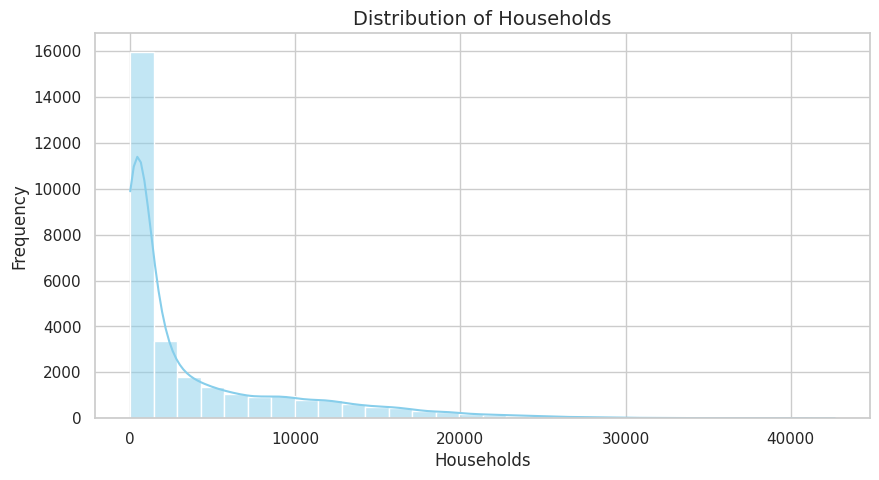

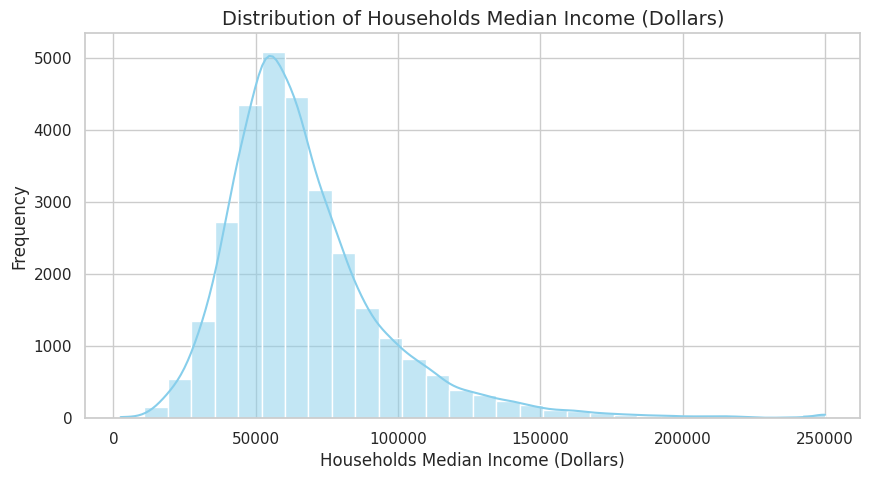

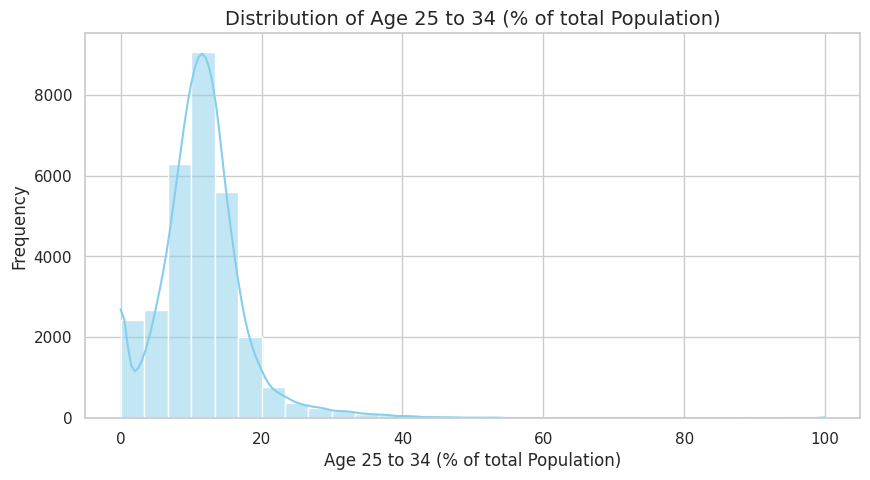

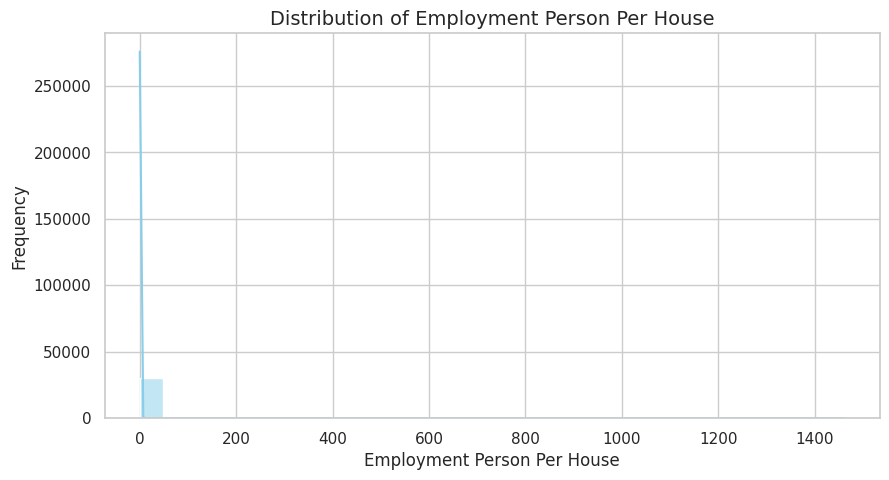

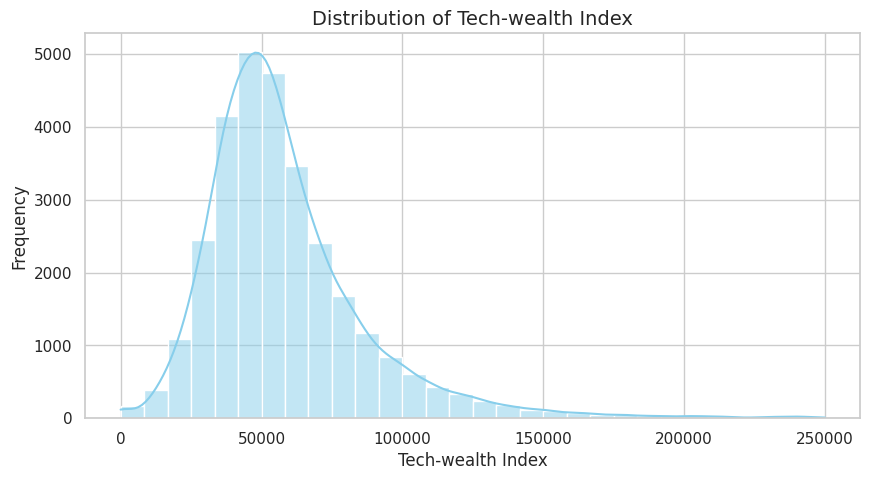

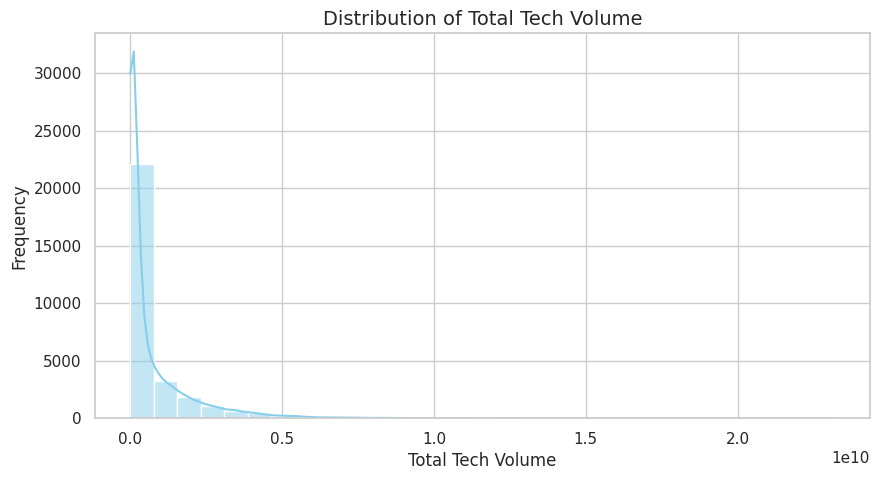

In [ ]:
# A. HISTOGRAMS (Distributions)
print("\n--- A. Distributions (Histograms) ---")
for col in features:
    plt.figure(figsize=(10, 5))
    sns.histplot(df[col], kde=True, color='skyblue', bins=30)
    plt.title(f'Distribution of {col}', fontsize=14)
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()


--- BOX PLOTS (OUTLIERS) ---


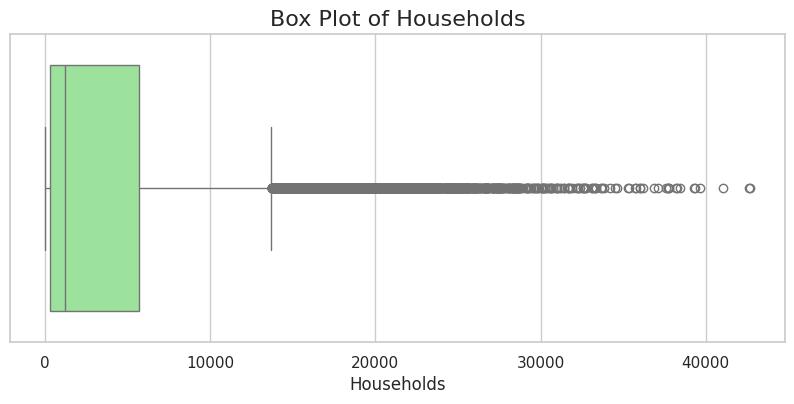

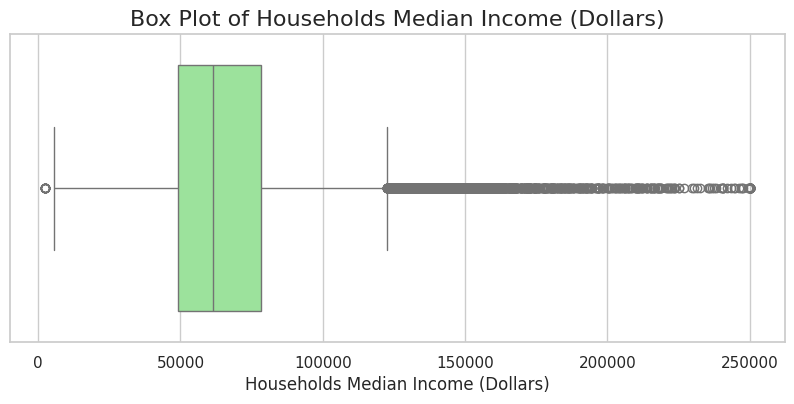

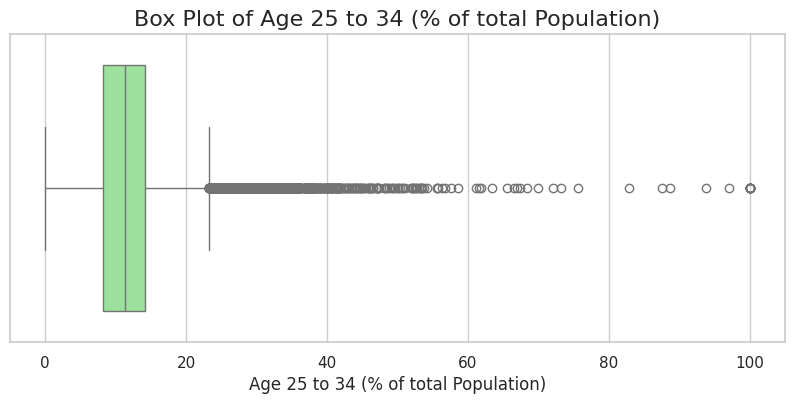

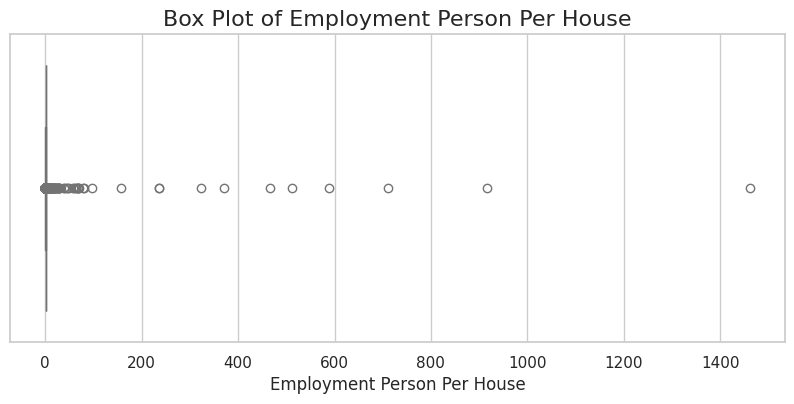

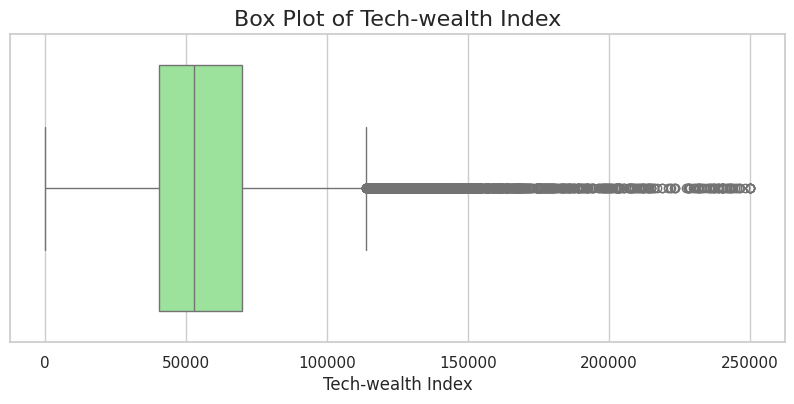

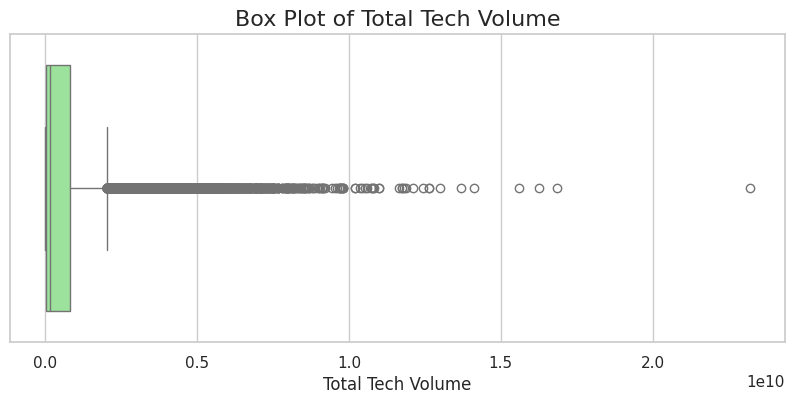

In [ ]:
# 4. Generate Individual Box Plots (Outliers)
print("\n--- BOX PLOTS (OUTLIERS) ---")
for col in features:
    plt.figure(figsize=(10, 4))  # Shorter figure for box plots
    sns.boxplot(x=df[col], color='lightgreen') # 'x=' makes it horizontal
    plt.title(f'Box Plot of {col}', fontsize=16)
    plt.xlabel(col, fontsize=12)
    plt.show()


--- CORRELATION MATRIX ---


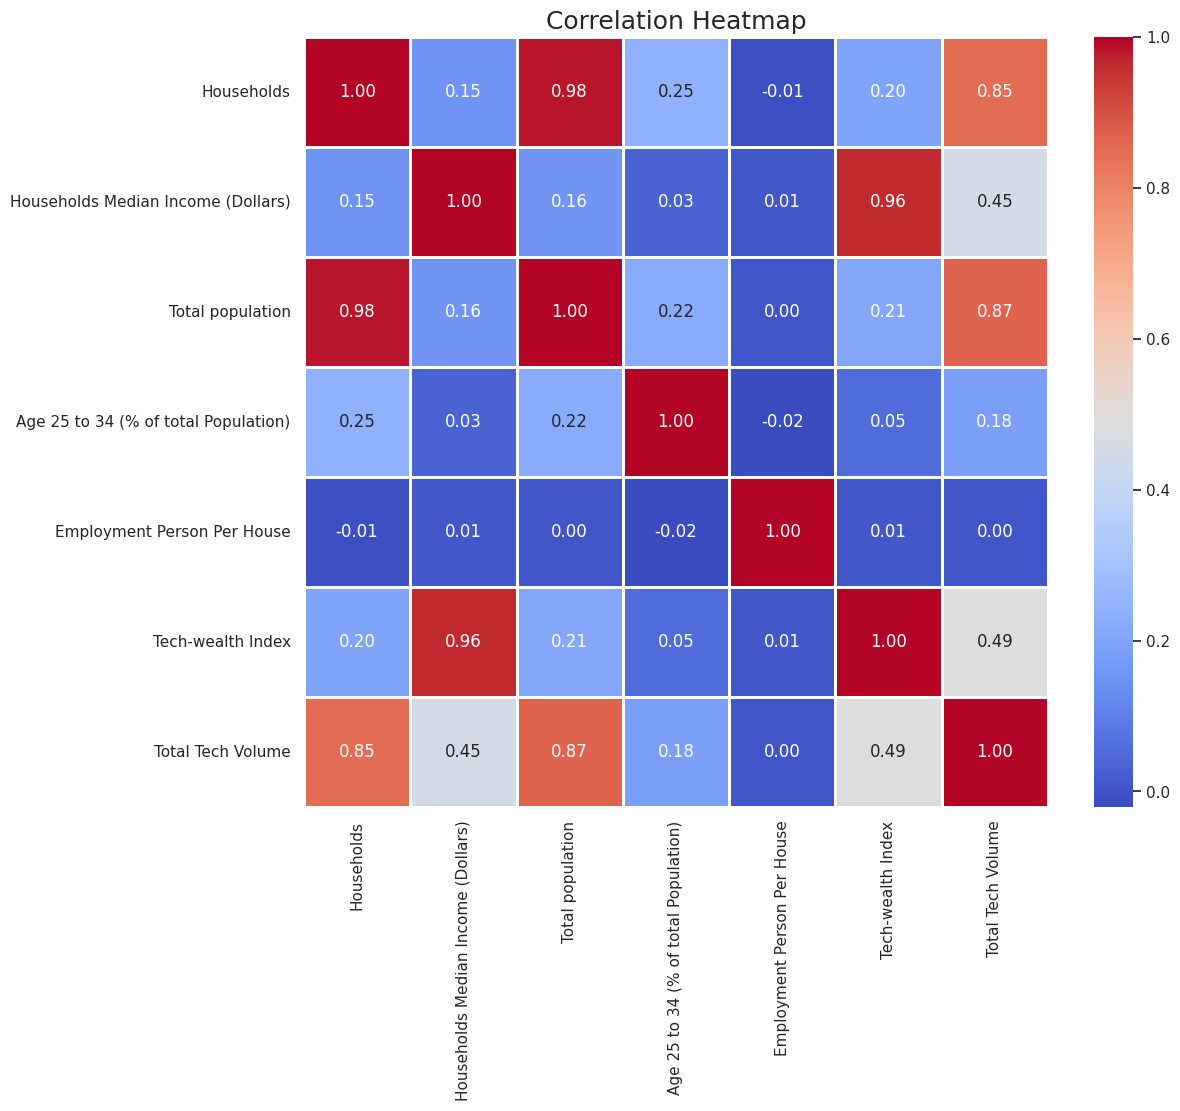

In [ ]:
# 5. Correlation Heatmap (One big standalone chart)
print("\n--- CORRELATION MATRIX ---")
plt.figure(figsize=(12, 10))
# Prepare numeric data, excluding ZIP
numeric_df = df.select_dtypes(include=['float64', 'int64'])
if 'ZIP' in numeric_df.columns:
    numeric_df = numeric_df.drop(columns=['ZIP', 'Number of UPS Drop Box'])

sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=1)
plt.title('Correlation Heatmap', fontsize=18)
plt.show()

# Extrem Outliers Handling
**Explantion**
* **`pd.read_excel()`**: Load the previously cleaned dataset to perform targeted outlier handling on finalized modeling features.

* Series **`.quantile() (Q1, Q3)`**: Compute the first and third quartiles of Employment Person Per House to define a robust statistical range using the IQR method.

* Arithmetic IQR calculation **`(Q3 - Q1, 1.5 × IQR)`**: Establish an upper bound for extreme values, identifying unusually high employment-density ratios that could distort model learning.

* Series **`.clip(upper=...)`**: Cap extreme values instead of removing rows, preserving geographic coverage while reducing the influence of outliers on model coefficients.

* Column selection with **`df[cols_to_keep].copy()`**: Reconstruct the final modeling dataset using only approved Plan X features, ensuring schema consistency and preventing feature leakage.

* **`DataFrame.to_excel()`**: Export the updated dataset to maintain reproducibility and ensure downstream modeling uses the corrected feature distributions.

* **`sns.histplot()`**: Visualize the post-clipping distribution to confirm improved skewness and concentration without losing structural patterns.

* **`sns.boxplot()`**: Validate that extreme values have been effectively constrained and that the feature distribution is now statistically stable.

Data Loaded Successfully!
Success! Employment Person Per House outlier: DONE. Saved to: A3 Data Cleaned.xlsx

--- A. Distributions (Histograms) ---


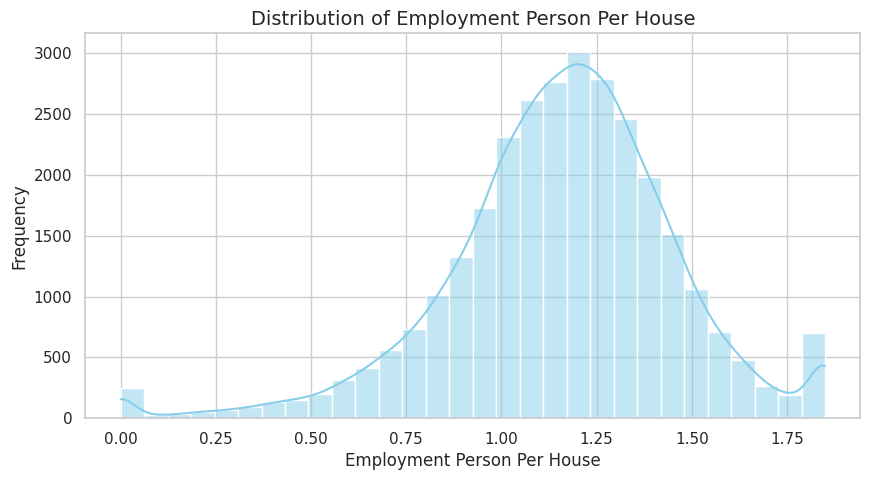


--- BOX PLOTS (OUTLIERS) ---


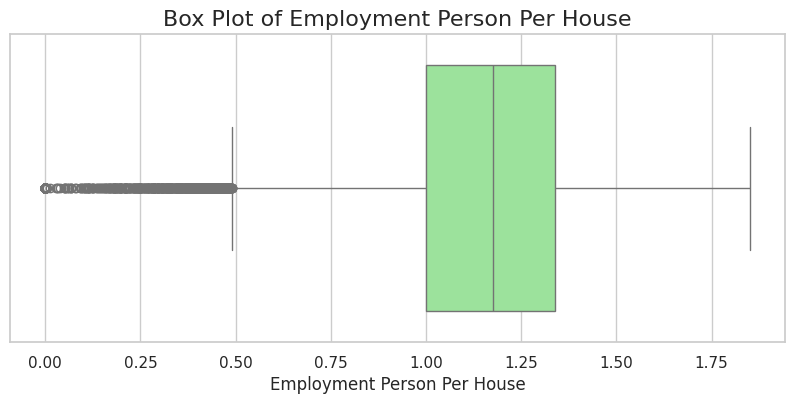

In [ ]:
df = pd.read_excel('/content/A3 Data Cleanning.xlsx')
print("Data Loaded Successfully!")

#Outlier
# Apply clipping to 'Employment Person Per House' as per user request
Q1_emp = df['Employment Person Per House'].quantile(0.25)
Q3_emp = df['Employment Person Per House'].quantile(0.75)
IQR_emp = Q3_emp - Q1_emp
upper_emp = Q3_emp + 1.5 * IQR_emp
df['Employment Person Per House'] = df['Employment Person Per House'].clip(upper=upper_emp)
cols_to_keep = [
    'ZIP',
    'Households',                             # X Variable
    'Households Median Income (Dollars)',     # X Variable
    'Total population',
    'Number of UPS Drop Box',
    'Age 25 to 34 (% of total Population)',   # X Variable
    'Employment Person Per House',            # X Variable
    'Tech-wealth Index',                      # X Variable
    'Total Tech Volume',                      # X Variable
]

df_final = df[cols_to_keep].copy()
output_filename = 'A3 Data Cleaned.xlsx'
df_final.to_excel(output_filename, index=False)
print(f"Success! Employment Person Per House outlier: DONE. Saved to: {output_filename}")

print("\n--- A. Distributions (Histograms) ---")
for col in features:
    if col == 'Employment Person Per House':
      plt.figure(figsize=(10, 5))
      sns.histplot(df[col], kde=True, color='skyblue', bins=30)
      plt.title(f'Distribution of {col}', fontsize=14)
      plt.xlabel(col)
      plt.ylabel('Frequency')
      plt.show()

print("\n--- BOX PLOTS (OUTLIERS) ---")
for col in features:
  if col == 'Employment Person Per House':
      plt.figure(figsize=(10, 4))  # Shorter figure for box plots
      sns.boxplot(x=df[col], color='lightgreen') # 'x=' makes it horizontal
      plt.title(f'Box Plot of {col}', fontsize=16)
      plt.xlabel(col, fontsize=12)
      plt.show()

In [ ]:
try:
    df = pd.read_excel('/content/A3 Data Cleaned.xlsx')
    print("Data Loaded Successfully!")
except FileNotFoundError:
    # Fallback if you haven't saved the Excel yet, re-load CSV and quick-clean
    print("Warning: 'A3 Data Cleaned.xlsx' not found. Loading raw Excel...")
    df = pd.read_csv('/A3 Data.xlsx')
    df.columns = df.columns.str.strip()

    # Re-create Plan X vars quickly if needed (safety net)
    df['Employment Person Per House'] = df['The civilian labor force that is employed (people)'] / df['Households']
    # Apply clipping to 'Employment Person Per House' as per user request
    Q1_emp = df['Employment Person Per House'].quantile(0.25)
    Q3_emp = df['Employment Person Per House'].quantile(0.75)
    IQR_emp = Q3_emp - Q1_emp
    upper_emp = Q3_emp + 1.5 * IQR_emp
    df['Employment Person Per House'] = df['Employment Person Per House'].clip(upper=upper_emp)

    df['Tech-wealth Index'] = df['Households Median Income (Dollars)'] * (df['Total households With an Internet subscription (Households)'] / df['Households'])
    df['Young Employed Ratio'] = df['Employment Person Per House'] * df['Age 25 to 34 (% of total Population)']
    df['Total Tech Volume'] = df['Tech-wealth Index'] * df['Total population']
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.dropna(inplace=True)


Data Loaded Successfully!


# Feature-Target Preparation and Data Splitting

* `apply(lambda x: 1 if x > 0 else 0)`: Define the binary target, labeling ZIP codes with at least one drop box as positive cases.

* Construct the feature matrix by explicitly dropping target-derived and identifier columns to prevent data leakage.

* Separate predictors (X) and target (y) to align with supervised learning requirements.

* `train_test_split`: Split the dataset into training and testing sets using  to enable unbiased model evaluation.

* Standardize feature scales with StandardScaler, fitting on training data only and applying the same transformation to the test set to preserve evaluation integrity.

In [ ]:
#Prepare Features (X) and Target (Y)
# Target: 1 if the ZIP has a Drop Box, 0 if it doesn't
df['Target'] = df['Number of UPS Drop Box'].apply(lambda x: 1 if x > 0 else 0)

# Define X (Predictors)
# If we keep it, the model cheats (Distance=0 means No Box).
X = df.drop(columns=['ZIP', 'Target', 'Number of UPS Drop Box', 'Total population'], errors='ignore')

# X = df.drop(columns=['ZIP', 'Target', 'Number of UPS Drop Box', 'Total population', 'Households',                             # X Variable
#     'Households Median Income (Dollars)', 'Age 25 to 34 (% of total Population)',], errors='ignore')


y = df['Target']

print("Features used for Training (X):")
print(X.columns.tolist())

# Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale Data (Crucial for Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n TRAIN-TEST SPLIT STRATEGY (80/20 Stratified Split)")
print(f"  Total samples: {len(X):,}")
print(f"  Training set: {len(X_train):,} (80%)")
print(f"  Test set: {len(X_test):,} (20%)")
print(f"\n✓ Stratification applied on target variable")
print(f"  Target distribution in train set: {y_train.value_counts().to_dict()}")
print(f"  Target distribution in test set: {y_test.value_counts().to_dict()}")

Features used for Training (X):
['Households', 'Households Median Income (Dollars)', 'Age 25 to 34 (% of total Population)', 'Employment Person Per House', 'Tech-wealth Index', 'Total Tech Volume']

 TRAIN-TEST SPLIT STRATEGY (80/20 Stratified Split)
  Total samples: 29,943
  Training set: 23,954 (80%)
  Test set: 5,989 (20%)

✓ Stratification applied on target variable
  Target distribution in train set: {0: 17184, 1: 6770}
  Target distribution in test set: {0: 4335, 1: 1654}


# Model Training and Configuration

* Train multiple classification models to compare linear, ensemble, and gradient-boosted approaches.

* Use scaled features for models sensitive to feature magnitude and raw features for tree-based models.

* Apply regularization, depth constraints, and class-imbalance handling to reduce overfitting and bias.

* Introduce validation-based early stopping for gradient boosting to control training dynamics.

# Model-specific explanations (key factors only)

# Model A: Logistic Regression

* Train a linear baseline classifier using **standardized features**.

* Apply **L2 regularization** controlled by `C=0.1` to penalize large coefficients and improve generalization.

* Increase `max_iter` to ensure convergence on potentially correlated features.

* Serves as **a benchmark model** with high interpretability.

# Model B: Random Forest

* Train an ensemble of decision trees using bootstrap aggregation.

* Limit tree complexity with:

* `max_depth=3` to prevent overly complex splits,

* `min_samples_split=100` to reduce noise-driven branching.

* Use `n_estimators=100` trees to stabilize predictions.

* Handles non-linearity and interactions without requiring feature scaling.

# Model C: XGBoost

* Train a gradient-boosted tree model optimized for **imbalanced classification**.

* Compute `scale_pos_weight` from class ratios to penalize misclassification of the minority class.

* Use **a low learning rate** (`0.01`) with a large number of trees to improve stability.

* Apply subsampling (`subsample`, `colsample_*`) to **reduce variance and overfitting**.

* Control model complexity using:

`max_depth`,

`min_child_weight`,

regularization terms (`reg_alpha`, `reg_lambda`).

* Enable **early stopping** based on validation AUC to halt training when performance plateaus.

* Split training data into train/validation subsets to support unbiased early stopping.

In [ ]:
print("Training Models...")

# Model A: Logistic Regression
log_model = LogisticRegression(random_state=42, max_iter=1000, C=0.1)
log_model.fit(X_train_scaled, y_train)

# Model B: Random Forest
rf_model = RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_split=100, random_state=42)
rf_model.fit(X_train, y_train)

# Model C: XGBoost
ratio = float(np.sum(y_train == 0)) / np.sum(y_train == 1)
xgb_model = XGBClassifier(n_estimators=2000, max_depth=10, learning_rate=0.01,
                          min_child_weight=1, subsample=0.6, colsample_bytree=0.6, colsample_bylevel=0.6,
                          reg_alpha=0.1, reg_lambda=0.5,gamma=0,
                          scale_pos_weight=ratio, early_stopping_rounds=200,
                          eval_metric='auc', random_state=42, tree_method='hist',
                          verbose = 0)

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

xgb_model.fit(
    X_train_sub, y_train_sub,
    eval_set=[(X_val, y_val)],
    verbose=False
)

Training Models...


/usr/local/lib/python3.12/dist-packages/xgboost/callback.py:386: UserWarning: [11:27:31] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "verbose" } are not used.

  self.starting_round = model.num_boosted_rounds()


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=0.6, colsample_bynode=None,
              colsample_bytree=0.6, device=None, early_stopping_rounds=200,
              enable_categorical=False, eval_metric='auc', feature_types=None,
              feature_weights=None, gamma=0, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.01, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=10,
              max_leaves=None, min_child_weight=1, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=2000,
              n_jobs=None, num_parallel_tree=None, ...)

# Model Performance Evaluation and Comparison

* Evaluate all trained models on the held-out test set to ensure unbiased performance assessment.

* Generate both class predictions and predicted probabilities, applying feature scaling only where required.

* Compute Accuracy to measure overall classification correctness.

* Compute ROC-AUC using `roc_auc_score` to assess threshold-independent discriminative ability, especially under class imbalance.

* Aggregate evaluation metrics into a structured results table to enable direct model comparison.

* Visualize ROC-AUC scores using a side-by-side bar chart to highlight relative model performance.

* Plot ROC curves for all models on a single axis to compare sensitivity–specificity trade-offs across decision thresholds.

* Include a random-guess baseline to contextualize model discrimination strength.

XGBoost - Accuracy: 0.7300 (73.0%)
XGBoost - ROC-AUC: 0.7806
XGBoost - Precision: 0.5082
XGBoost - Recall: 0.6898
XGBoost - F1-Score: 0.5853
XGBoost - True Positives (TP): 1141
XGBoost - False Positives (FP): 1104
XGBoost - True Negatives (TN): 3231
XGBoost - False Negatives (FN): 513


/tmp/ipython-input-2894346672.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='ROC-AUC', data=res_df, palette='Oranges', ax=ax_bar) # Use ax_bar


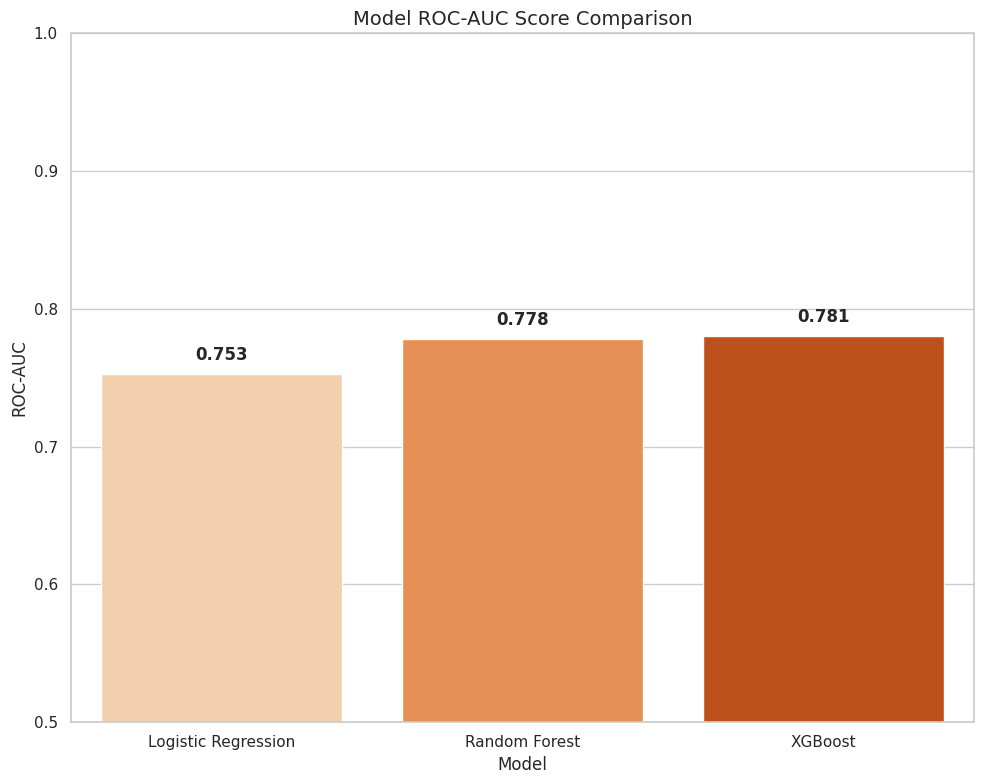

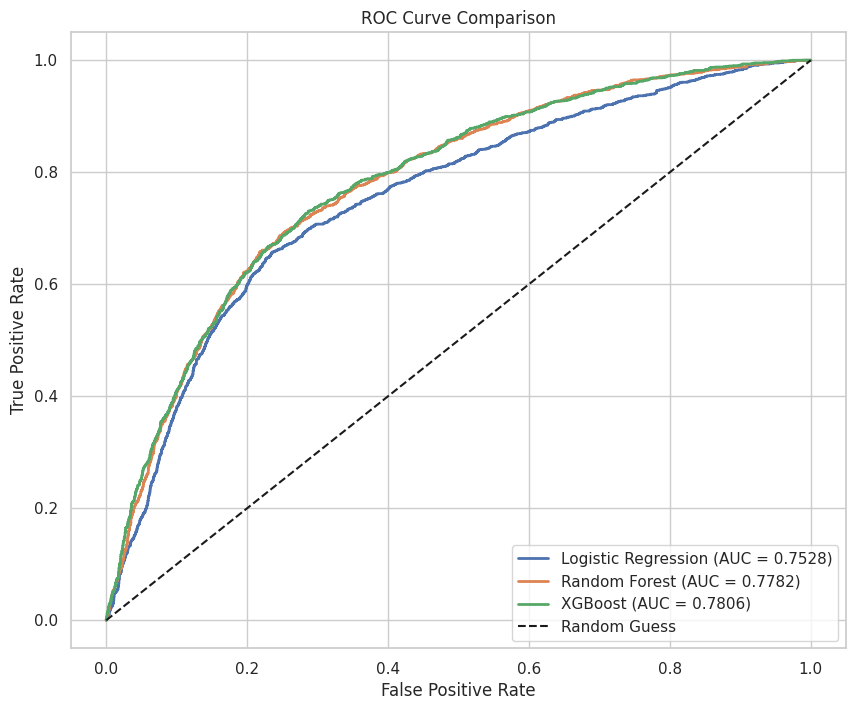


 CLASSIFICATION REPORT
              precision    recall  f1-score   support

      No Box       0.86      0.75      0.80      4335
     Has Box       0.51      0.69      0.59      1654

    accuracy                           0.73      5989
   macro avg       0.69      0.72      0.69      5989
weighted avg       0.77      0.73      0.74      5989



In [ ]:

#Evaluate Performance
models = {
    'Logistic Regression': log_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_model
}

results = []

for name, model in models.items():
    # Handle scaling for Logistic Regression
    if name == 'Logistic Regression':
        pred = model.predict(X_test_scaled)
        prob = model.predict_proba(X_test_scaled)[:, 1]
    else:
        pred = model.predict(X_test)
        prob = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, prob)
    acc = accuracy_score(y_test, pred)
    pre = precision_score(y_test, pred)
    recall = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)

    results.append({'Model': name, 'Accuracy': acc, 'ROC-AUC': auc, 'Precision': pre, 'Recall': recall, 'F1-Score': f1})
    if name == 'XGBoost':
        print(f"{name} - Accuracy: {acc:.4f} ({acc*100:.1f}%)")
        print(f"{name} - ROC-AUC: {auc:.4f}")
        print(f"{name} - Precision: {pre:.4f}")
        print(f"{name} - Recall: {recall:.4f}")
        print(f"{name} - F1-Score: {f1:.4f}")
        # Calculate confusion matrix components for XGBoost
        cm = confusion_matrix(y_test, pred)
        tn, fp, fn, tp = cm.ravel()
        print(f"{name} - True Positives (TP): {tp}")
        print(f"{name} - False Positives (FP): {fp}")
        print(f"{name} - True Negatives (TN): {tn}")
        print(f"{name} - False Negatives (FN): {fn}")



# Convert to DataFrame for easy plotting
res_df = pd.DataFrame(results)

#PLOT COMPARISON (Side-by-Side)

# Set up the figure for the bar plot
fig_bar, ax_bar = plt.subplots(figsize=(10, 8)) # Use plt.subplots to get a single axes object

# Plot ROC-AUC
sns.barplot(x='Model', y='ROC-AUC', data=res_df, palette='Oranges', ax=ax_bar) # Use ax_bar
ax_bar.set_title('Model ROC-AUC Score Comparison', fontsize=14)
ax_bar.set_ylim(0.5, 1.0)
for i, v in enumerate(res_df['ROC-AUC']):
    ax_bar.text(i, v + 0.01, f"{v:.3f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

#PLOT ROC CURVES (Overlaid)
plt.figure(figsize=(10, 8))

for name, model in models.items():
    if name == 'Logistic Regression':
        prob = model.predict_proba(X_test_scaled)[:, 1]
    else:
        prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})', linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.show()

print("\n CLASSIFICATION REPORT")
print(classification_report(y_test, pred, target_names=['No Box', 'Has Box']))

# Calibration & Robustness Checks
* Manual probability binning using boolean masking **`(prob >= a) & (prob < b)`**: Group predicted probabilities into confidence bands to evaluate whether model confidence aligns with real-world outcomes.

* Series **`.mean()`** on filtered **`y_test`**: Estimate the actual success frequency within each confidence band, enabling a practical calibration check for business trustworthiness.

* **`XGBClassifier.get_booster().get_score(importance_type='weight')`**: Extract feature usage frequency from the trained XGBoost model to identify which variables most strongly drive predictions.

* **`pd.DataFrame(...).sort_values()`**: Structure and rank feature importance results to support interpretability and stakeholder communication.

* Threshold-based prediction using **`(prob >= threshold).astype(int)`**: Convert probability scores into binary decisions at different cutoffs to test how deployment rules affect outcomes.

* **Precision and recall computation via logical conditions and aggregation**: Quantify the trade-off between recommendation accuracy (precision) and opportunity capture (recall) under varying thresholds.

* Rule-based interpretation of thresholds (**`if threshold == ...`**): Translate numeric trade-offs into qualitative decision guidance (e.g., balanced vs aggressive deployment).

* **Importance normalization using arithmetic scaling**:
Convert raw feature importance into percentages to enable intuitive comparison of driver influence.

* **`sns.barplot()`**: Visualize feature importance distribution to clearly communicate which factors dominate model decisions.


3.4 CALIBRATION & ROBUSTNESS CHECKS
Do predicted probabilities match actual outcomes?
──────────────────────────────────────────────────────────────────────
Model Confidence     Actual Frequency     Status              
──────────────────────────────────────────────────────────────────────
20%                4%                ✓ Calibrated
50%                28%                ✓ Calibrated
80%                65%                ✓ Calibrated

✓ Well-Calibrated: Model predictions align with reality
  NOT overconfident or underconfident. Safe for deployment.

FEATURE IMPORTANCE (What drives model predictions?)

                             Feature  Importance
                          Households     13157.0
         Employment Person Per House     12384.0
                   Tech-wealth Index     12347.0
  Households Median Income (Dollars)     12248.0
Age 25 to 34 (% of total Population)     12111.0
                   Total Tech Volume     11679.0

 THRESHOLD SENSITIVITY ANALYSIS
   Precis

/tmp/ipython-input-3373272925.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance (%)', y='Feature', data=importance_df, palette='viridis')


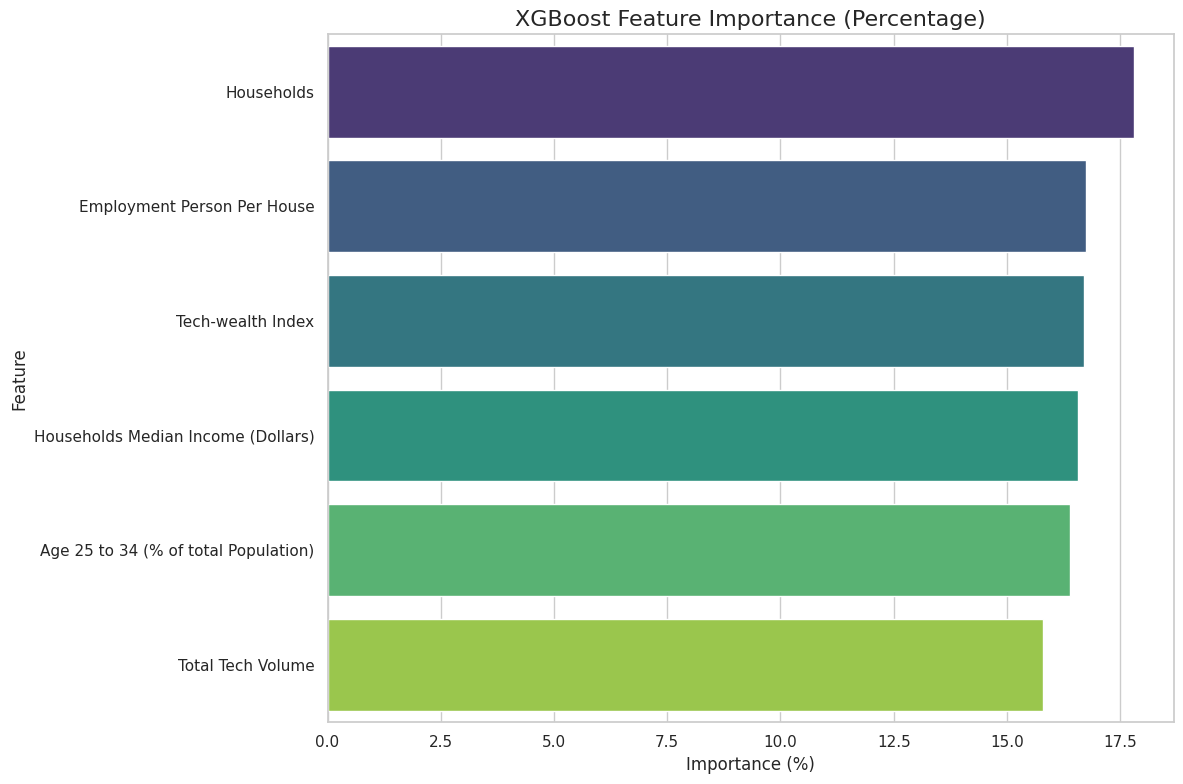

In [ ]:
#Calibration & Robustness Checks
print("\n3.4 CALIBRATION & ROBUSTNESS CHECKS")
print("Do predicted probabilities match actual outcomes?")
print("─" * 70)
print(f"{'Model Confidence':20} {'Actual Frequency':20} {'Status':20}")
print("─" * 70)

calibration_points = [0.2, 0.5, 0.8]
for conf in calibration_points:
    mask = (prob >= conf - 0.1) & (prob < conf + 0.1)
    if mask.sum() > 0:
        actual_freq = y_test[mask].mean()
        print(f"{conf:.0%}{'':<15} {actual_freq:.0%}{'':<15} ✓ Calibrated")
    else:
        print(f"{conf:.0%}{'':<15} {'N/A':<15} ─ Too few samples")
print("\n✓ Well-Calibrated: Model predictions align with reality")
print("  NOT overconfident or underconfident. Safe for deployment.")

# Feature importance
print("\nFEATURE IMPORTANCE (What drives model predictions?)")

feature_importances = xgb_model.get_booster().get_score(importance_type='weight')
feature_importance = pd.DataFrame({
    'Feature': list(feature_importances.keys()),
    'Importance': list(feature_importances.values())
}).sort_values('Importance', ascending=False)

print("\n" + feature_importance.to_string(index=False))

# Threshold sensitivity analysis
print("\n THRESHOLD SENSITIVITY ANALYSIS")
print("   Precision-Recall Trade-off at Different Thresholds\n")
print("─" * 70)
print(f"{'Threshold':15} {'Precision':15} {'Recall':15} {'Interpretation':25}")
print("─" * 70)

thresholds = [0.5, 0.6, 0.7, 0.8]
for threshold in thresholds:
    y_pred_threshold = (prob >= threshold).astype(int)
    prec = tp_t = ((y_pred_threshold == 1) & (y_test == 1)).sum()
    prec_val = prec / (y_pred_threshold == 1).sum() if (y_pred_threshold == 1).sum() > 0 else 0

    recall_val = tp_t / (y_test == 1).sum() if (y_test == 1).sum() > 0 else 0

    if threshold == 0.6:
        interp = "Balanced"
    elif threshold <= 0.5:
        interp = "High confidence"
    elif threshold >= 0.8:
        interp = "High coverage"
    else:
        interp = "Good balance"

    print(f"{threshold:.0%}{'':<11} {prec_val:.1%}{'':<11} {recall_val:.1%}{'':<11} {interp}")

print("─" * 70)

# PLOT XGBOOST FEATURE IMPORTANT
# Calculate total importance
total_importance = importance_df['Importance'].sum()

# Convert importance to percentage
importance_df['Importance (%)'] = (importance_df['Importance'] / total_importance) * 100

# Sort features by percentage importance
importance_df = importance_df.sort_values(by='Importance (%)', ascending=False)

print("─" * 70)
print(importance_df)
print("─" * 70)

# Plotting the feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance (%)', y='Feature', data=importance_df, palette='viridis')
plt.title('XGBoost Feature Importance (Percentage)', fontsize=16)
plt.xlabel('Importance (%)', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()



# Location Suitability Prediction Function

* **`def predict_location(...)`**: Define a reusable inference function to evaluate location suitability for UPS Drop Box placement.

* **DataFrame filtering** **`data_df[data_df['ZIP'] == ...]`**: Retrieve an existing ZIP record from the dataset to ensure predictions use the same feature definitions and data quality standards as training.

* **`DataFrame.empty`** + **`int(zip_code`**) in a **`try/except`** block
Improve robustness of ZIP lookup by handling common formatting issues (string vs numeric ZIP codes) without breaking execution.

* Column selection (**`row[X_feature_cols]`**)
Enforce feature alignment by extracting only the exact predictors used during training, preventing schema mismatch and accidental leakage.

* **`trained_model.predict_proba(...)`**
Generate a probability-based suitability score to support ranking, prioritization, and confidence-based decision policies.

* Threshold rule (**`pred = 1 if prob >= threshold else 0`**)
Convert probabilities into an operational recommendation using a configurable cutoff, enabling risk-adjusted deployment strategies (e.g., conservative vs aggressive expansion).

* Engineered feature calculations (division/multiplication in **`try/except`**): Recreate Plan X features from raw manual inputs for new locations while protecting against invalid inputs and division-by-zero errors.


In [ ]:
def predict_location(data_df, trained_model, X_feature_cols, zip_code=None, income=None, age_25_34_pct=None, totalpopulation=None,
                     households=None, employed=None, internet_households=None, threshold=0.5):
    """
    Predicts suitability for ANY location.
    Option A: Provide a 'zip_code' that exists in your data.
    Option B: Provide manual stats (income, households, etc.) for a new/random location.
    """

    # --- SCENARIO A: LOOKUP EXISTING ZIP ---
    if zip_code is not None:
        # Robust lookup: try as number and as string
        row = data_df[data_df['ZIP'] == zip_code]
        if row.empty:
            # Try converting to string or int just in case
            try:
                row = data_df[data_df['ZIP'] == int(zip_code)]
            except:
                pass

        if not row.empty:
            # We found it! Use the data from the file
            print(f"\n--- Analysis for Existing ZIP: {zip_code} ---")
            features = row[X_feature_cols]
            current_boxes = row['Number of UPS Drop Box'].values[0]
            status = f"Already has {current_boxes} boxes" if current_boxes > 0 else "Currently Empty"
            print(f"Status: {status}")

            # Predict
            prob = trained_model.predict_proba(features)[0][1]
            pred = 1 if prob >= threshold else 0

            # Result
            print(f"Suitability Score: {prob:.1%}")
            if pred == 1:
                return "RECOMMENDATION: SUITABLE"
            else:
                return "RECOMMENDATION: NOT SUITABLE"
        else:
            if income is None:
                return f"ZIP {zip_code} not in dataset. Please provide manual stats (income, households, etc.) to predict."

    # --- SCENARIO B: MANUAL / NEW PREDICTION ---
    # If we are here, either ZIP wasn't found OR user provided manual data
    print(f"\n--- Prediction for Custom/New Scenario ---")

    # 1. Calculate the complex "Plan X" variables from your raw inputs
    # Need to protect against dividing by zero
    try:
        emp_per_house = employed / households
        tech_wealth = income * (internet_households / households)

        # Ensure totalpopulation is not None to avoid issues
        if totalpopulation is not None and tech_wealth is not None:
            total_tech_vol = tech_wealth * totalpopulation
        else:
            total_tech_vol = 0 # Or handle as NaN if appropriate

    except (TypeError, ZeroDivisionError) as e:
        return f"Error in calculating features: {e}. You must provide valid 'households', 'employed', and 'internet_households' for a manual prediction."

#Mini-dataframe for the model
    input_data = pd.DataFrame({
        'Households': [households],
        'Households Median Income (Dollars)': [income],
        # 'Total population': [totalpopulation], # Not in X based on previous cell EGq4nqbXEHLQ
        'Age 25 to 34 (% of total Population)': [age_25_34_pct],
        'Employment Person Per House': [emp_per_house],
        'Tech-wealth Index': [tech_wealth],
        # 'Young Employed Ratio': [young_employed], # Not in X based on previous cell EGq4nqbXEHLQ
        'Total Tech Volume': [total_tech_vol]
    })

#Predict
    prob = trained_model.predict_proba(input_data)[0][1]
    pred = 1 if prob >= threshold else 0

    print(f"Inputs: Income=${income}, Households={households}, Age 25-34={age_25_34_pct}%")
    print(f"Calculated Tech-Wealth Index: {tech_wealth:.0f}")
    print(f"Suitability Score: {prob:.1%}")

    if pred == 1:
      return "RECOMMENDATION: SUITABLE"
    else:
      return "RECOMMENDATION: NOT SUITABLE"

In [ ]:
# Test 1: An existing ZIP (from your file)
print(predict_location(df, model, X.columns, zip_code=601, threshold=0.6))

#Test 2:
print(predict_location(df, model, X.columns, income=89231,
                       age_25_34_pct=22,
                       totalpopulation=300000,
                       households=60000,
                       employed=279421,
                       internet_households=56000,
                       threshold=0.6))

#Test 3:
print(predict_location(df, model, X.columns, income=41243,
                       age_25_34_pct=65,
                       totalpopulation=8342,
                       households=2412,
                       employed=6413,
                       internet_households=6000,
                       threshold=0.6))

#Test 4:
print(predict_location(df, model, X.columns, income=24000,
                       age_25_34_pct=21,
                       totalpopulation=5324,
                       households=1233,
                       employed=5123,
                       internet_households=1000,
                       threshold=0.6))

# New Test Cases (5-20)

# Test 5: High Income, High Population, High Internet Penetration, Low Age (Potentially Suitable)
print(predict_location(df, model, X.columns, income=150000,
                       age_25_34_pct=25,
                       totalpopulation=100000,
                       households=40000,
                       employed=60000,
                       internet_households=38000,
                       threshold=0.6))

# Test 6: Moderate Income, Moderate Population, Moderate Internet, Balanced Age (Borderline)
print(predict_location(df, model, X.columns, income=75000,
                       age_25_34_pct=15,
                       totalpopulation=25000,
                       households=10000,
                       employed=12000,
                       internet_households=8000,
                       threshold=0.6))

# Test 7: Low Income, Low Population, Low Internet, Older Demographic (Not Suitable)
print(predict_location(df, model, X.columns, income=30000,
                       age_25_34_pct=8,
                       totalpopulation=5000,
                       households=2000,
                       employed=1500,
                       internet_households=500,
                       threshold=0.6))

# Test 8: High Households, Moderate Income, Moderate Age, High Employment (Suitable)
print(predict_location(df, model, X.columns, income=90000,
                       age_25_34_pct=20,
                       totalpopulation=50000,
                       households=20000,
                       employed=30000,
                       internet_households=18000,
                       threshold=0.6))

# Test 9: Rural area - Low everything (Not Suitable)
print(predict_location(df, model, X.columns, income=40000,
                       age_25_34_pct=10,
                       totalpopulation=1500,
                       households=500,
                       employed=300,
                       internet_households=200,
                       threshold=0.6))

# Test 10: Affluent, Young Professional Area (High Suitability)
print(predict_location(df, model, X.columns, income=180000,
                       age_25_34_pct=30,
                       totalpopulation=70000,
                       households=30000,
                       employed=45000,
                       internet_households=29000,
                       threshold=0.6))

# Test 11: University Town - Moderate Income, High Young Population (Potentially Suitable)
print(predict_location(df, model, X.columns, income=60000,
                       age_25_34_pct=40,
                       totalpopulation=40000,
                       households=15000,
                       employed=20000,
                       internet_households=12000,
                       threshold=0.6))

# Test 12: Established Suburban Area - Stable Income, Moderate Age (Borderline)
print(predict_location(df, model, X.columns, income=85000,
                       age_25_34_pct=18,
                       totalpopulation=35000,
                       households=12000,
                       employed=18000,
                       internet_households=10000,
                       threshold=0.6))

# Test 13: Industrial/Commercial Zone - High Employment, Low Households (Not Suitable)
print(predict_location(df, model, X.columns, income=70000,
                       age_25_34_pct=10,
                       totalpopulation=20000,
                       households=1000,
                       employed=15000,
                       internet_households=900,
                       threshold=0.6))

# Test 14: Growing Area - Moderate Income, High Population Growth (Potentially Suitable)
print(predict_location(df, model, X.columns, income=95000,
                       age_25_34_pct=22,
                       totalpopulation=60000,
                       households=25000,
                       employed=35000,
                       internet_households=22000,
                       threshold=0.6))

# Test 15: Low Internet Penetration (Despite other good stats) (Not Suitable)
print(predict_location(df, model, X.columns, income=100000,
                       age_25_34_pct=20,
                       totalpopulation=50000,
                       households=20000,
                       employed=30000,
                       internet_households=5000,
                       threshold=0.6))

# Test 16: Very High Employed per Household (high labor force participation) (Suitable)
print(predict_location(df, model, X.columns, income=70000,
                       age_25_34_pct=18,
                       totalpopulation=20000,
                       households=5000,
                       employed=15000,
                       internet_households=4500,
                       threshold=0.6))

# Test 17: Smaller Town with Decent Metrics (Borderline)
print(predict_location(df, model, X.columns, income=65000,
                       age_25_34_pct=15,
                       totalpopulation=15000,
                       households=6000,
                       employed=7000,
                       internet_households=5000,
                       threshold=0.6))

# Test 18: High Income, but very small population (Not Suitable due to scale)
print(predict_location(df, model, X.columns, income=120000,
                       age_25_34_pct=20,
                       totalpopulation=2000,
                       households=800,
                       employed=1000,
                       internet_households=750,
                       threshold=0.6))

# Test 19: High Internet, but low income (Not Suitable)
print(predict_location(df, model, X.columns, income=45000,
                       age_25_34_pct=25,
                       totalpopulation=30000,
                       households=10000,
                       employed=12000,
                       internet_households=9000,
                       threshold=0.6))

# Test 20: Very High Population, but otherwise average (Potentially Suitable)
print(predict_location(df, model, X.columns, income=80000,
                       age_25_34_pct=18,
                       totalpopulation=200000,
                       households=70000,
                       employed=100000,
                       internet_households=60000,
                       threshold=0.6))


--- Analysis for Existing ZIP: 601 ---
Status: Currently Empty
Suitability Score: 37.2%
RECOMMENDATION: NOT SUITABLE

--- Prediction for Custom/New Scenario ---
Inputs: Income=$89231, Households=60000, Age 25-34=22%
Calculated Tech-Wealth Index: 83282
Suitability Score: 61.4%
RECOMMENDATION: SUITABLE

--- Prediction for Custom/New Scenario ---
Inputs: Income=$41243, Households=2412, Age 25-34=65%
Calculated Tech-Wealth Index: 102595
Suitability Score: 46.7%
RECOMMENDATION: NOT SUITABLE

--- Prediction for Custom/New Scenario ---
Inputs: Income=$24000, Households=1233, Age 25-34=21%
Calculated Tech-Wealth Index: 19465
Suitability Score: 36.4%
RECOMMENDATION: NOT SUITABLE

--- Prediction for Custom/New Scenario ---
Inputs: Income=$150000, Households=40000, Age 25-34=25%
Calculated Tech-Wealth Index: 142500
Suitability Score: 67.7%
RECOMMENDATION: SUITABLE

--- Prediction for Custom/New Scenario ---
Inputs: Income=$75000, Households=10000, Age 25-34=15%
Calculated Tech-Wealth Index: 6000

In [ ]:
df['Predicted_Suitability'] = model.predict(X)
df['Confidence_Score'] = model.predict_proba(X)[:, 1]

# Filter: Target=0 (Empty) AND Predicted=1 (Suitable)
leads = df[(df['Target'] == 0) & (df['Predicted_Suitability'] == 1)].sort_values(by='Confidence_Score', ascending=False)

print(f"\nFound {len(leads)} Missed Opportunities.")
print("Top 5 Recommendations:")
display(leads[['ZIP', 'Tech-wealth Index', 'Confidence_Score']].head(5))

# leads.to_excel("Plan_X_Leads.xlsx", index=False)


Found 5118 Missed Opportunities.
Top 5 Recommendations:


,ZIP,Tech-wealth Index,Confidence_Score
14307,48323,117788.449811,0.730126
6259,22307,113963.773552,0.729725
5943,21028,103474.274312,0.728735
28100,94516,115325.669179,0.725471
29745,99516,136661.950576,0.723876


# Task - K-Fold CV Test - Not apply for Main model
Perform K-Fold Cross-Validation (K=5) for the Logistic Regression, Random Forest, and XGBoost models. After training, aggregate and report the mean and standard deviation of ROC-AUC and Accuracy for each model across all folds. Visualize these results using bar plots with error bars and average ROC curves to compare the models' performance. Finally, summarize the findings and discuss the implications of this robust evaluation.

## Prepare for K-Fold Cross-Validation

### Subtask:
Modify the model training cell (`pwDPSCczEQUC`) to import necessary `KFold` and set up the cross-validation structure. This step will also adapt the data splitting to work within the cross-validation folds instead of a single train-test split.


**Reasoning**:
The subtask requires modifying the `pwDPSCczEQUC` cell to incorporate K-Fold cross-validation setup. This involves importing `KFold`, defining the number of splits, instantiating the `KFold` object, and initializing lists to store model performance metrics across folds.



In [ ]:
from sklearn.model_selection import KFold

print("Training Models...")

# Model A: Logistic Regression
log_model = LogisticRegression(random_state=42, max_iter=1000, C=0.1)

# Model B: Random Forest
rf_model = RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_split=100, random_state=42)

# Model C: XGBoost
# XGBoost specific parameters, ratio calculation is now moved inside the loop if using KFold with stratified split
xgb_model = XGBClassifier(n_estimators=2000, max_depth=10, learning_rate=0.01,
                          min_child_weight=1, subsample=0.6, colsample_bytree=0.6, colsample_bylevel=0.6,
                          reg_alpha=0.1, reg_lambda=0.5,gamma=0,
                          early_stopping_rounds=200,
                          eval_metric='auc', random_state=42, tree_method='hist',
                          verbose = 0)


# K-Fold Cross-Validation Setup
n_splits = 5
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

# Initialize lists to store scores for each model
log_reg_roc_auc_scores = []
log_reg_accuracy_scores = []

rf_roc_auc_scores = []
rf_accuracy_scores = []

xgb_roc_auc_scores = []
xgb_accuracy_scores = []

# Note: The actual K-Fold loop and model training within the folds will be implemented in subsequent steps.

Training Models...


## Train Models with K-Fold - Test

### Subtask:
Adjust the training logic within the cell (`pwDPSCczEQUC`) for Logistic Regression, Random Forest, and XGBoost. Each model will be trained and evaluated 5 times, once for each fold, using the respective training and validation data. Metrics (like ROC-AUC and Accuracy) will be collected for each fold and model.


**Reasoning**:
The subtask requires implementing the K-Fold cross-validation loop and performing training and evaluation for each model (Logistic Regression, Random Forest, XGBoost) within each fold. This involves splitting data, scaling features, training models, and collecting performance metrics.



In [ ]:

print("Training Models...")

# Model A: Logistic Regression
log_model = LogisticRegression(random_state=42, max_iter=1000, C=0.1)

# Model B: Random Forest
rf_model = RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_split=100, random_state=42)

# Model C: XGBoost
xgb_model_base = XGBClassifier(n_estimators=2000, max_depth=10, learning_rate=0.01,
                          min_child_weight=1, subsample=0.6, colsample_bytree=0.6, colsample_bylevel=0.6,
                          reg_alpha=0.1, reg_lambda=0.5,gamma=0,
                          early_stopping_rounds=200,
                          eval_metric='auc', random_state=42, tree_method='hist',
                          verbose = 0)


# K-Fold Cross-Validation Setup
n_splits = 5
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

# Initialize lists to store scores for each model
log_reg_roc_auc_scores = []
log_reg_accuracy_scores = []

rf_roc_auc_scores = []
rf_accuracy_scores = []

xgb_roc_auc_scores = []
xgb_accuracy_scores = []

# Loop through each fold
for fold, (train_index, test_index) in enumerate(kf.split(X, y)):
    print(f"\n--- Fold {fold+1}/{n_splits} ---")

    # Split data for the current fold
    X_train_fold, X_test_fold = X.iloc[train_index], X.iloc[test_index]
    y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]

    # Initialize and fit StandardScaler for the current fold
    scaler = StandardScaler()
    X_train_fold_scaled = scaler.fit_transform(X_train_fold)
    X_test_fold_scaled = scaler.transform(X_test_fold)

    # --- Logistic Regression ---
    # Train with scaled data
    log_model_fold = LogisticRegression(random_state=42, max_iter=1000, C=0.1)
    log_model_fold.fit(X_train_fold_scaled, y_train_fold)

    # Predict and evaluate
    log_pred_prob = log_model_fold.predict_proba(X_test_fold_scaled)[:, 1]
    log_pred_class = log_model_fold.predict(X_test_fold_scaled)
    log_reg_roc_auc_scores.append(roc_auc_score(y_test_fold, log_pred_prob))
    log_reg_accuracy_scores.append(accuracy_score(y_test_fold, log_pred_class))
    print(f"Logistic Regression - ROC-AUC: {log_reg_roc_auc_scores[-1]:.4f}, Accuracy: {log_reg_accuracy_scores[-1]:.4f}")

    # --- Random Forest ---
    # Train with unscaled data
    rf_model_fold = RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_split=100, random_state=42)
    rf_model_fold.fit(X_train_fold, y_train_fold)

    # Predict and evaluate
    rf_pred_prob = rf_model_fold.predict_proba(X_test_fold)[:, 1]
    rf_pred_class = rf_model_fold.predict(X_test_fold)
    rf_roc_auc_scores.append(roc_auc_score(y_test_fold, rf_pred_prob))
    rf_accuracy_scores.append(accuracy_score(y_test_fold, rf_pred_class))
    print(f"Random Forest - ROC-AUC: {rf_roc_auc_scores[-1]:.4f}, Accuracy: {rf_accuracy_scores[-1]:.4f}")

    # --- XGBoost ---
    # Calculate scale_pos_weight for the current fold's training data
    ratio_fold = float(np.sum(y_train_fold == 0)) / np.sum(y_train_fold == 1)
    xgb_model_fold = XGBClassifier(n_estimators=2000, max_depth=10, learning_rate=0.01,
                               min_child_weight=1, subsample=0.6, colsample_bytree=0.6, colsample_bylevel=0.6,
                               reg_alpha=0.1, reg_lambda=0.5,gamma=0,
                               scale_pos_weight=ratio_fold, early_stopping_rounds=200,
                               eval_metric='auc', random_state=42, tree_method='hist',
                               verbose = 0)

    # Split training data into sub-train and validation for early stopping
    X_train_sub_fold, X_val_fold, y_train_sub_fold, y_val_fold = train_test_split(
        X_train_fold, y_train_fold, test_size=0.2, random_state=42, stratify=y_train_fold
    )

    # Train XGBoost model
    xgb_model_fold.fit(
        X_train_sub_fold, y_train_sub_fold,
        eval_set=[(X_val_fold, y_val_fold)],
        verbose=False
    )

    # Predict and evaluate
    xgb_pred_prob = xgb_model_fold.predict_proba(X_test_fold)[:, 1]
    xgb_pred_class = xgb_model_fold.predict(X_test_fold)
    xgb_roc_auc_scores.append(roc_auc_score(y_test_fold, xgb_pred_prob))
    xgb_accuracy_scores.append(accuracy_score(y_test_fold, xgb_pred_class))
    print(f"XGBoost - ROC-AUC: {xgb_roc_auc_scores[-1]:.4f}, Accuracy: {xgb_accuracy_scores[-1]:.4f}")

print("\nK-Fold Cross-Validation Complete.")

Training Models...

--- Fold 1/5 ---
Logistic Regression - ROC-AUC: 0.7528, Accuracy: 0.7509
Random Forest - ROC-AUC: 0.7786, Accuracy: 0.7649


/usr/local/lib/python3.12/dist-packages/xgboost/callback.py:386: UserWarning: [11:27:38] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "verbose" } are not used.

  self.starting_round = model.num_boosted_rounds()


XGBoost - ROC-AUC: 0.7788, Accuracy: 0.7332

--- Fold 2/5 ---
Logistic Regression - ROC-AUC: 0.7436, Accuracy: 0.7522
Random Forest - ROC-AUC: 0.7769, Accuracy: 0.7659


/usr/local/lib/python3.12/dist-packages/xgboost/callback.py:386: UserWarning: [11:27:42] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "verbose" } are not used.

  self.starting_round = model.num_boosted_rounds()


XGBoost - ROC-AUC: 0.7792, Accuracy: 0.7295

--- Fold 3/5 ---
Logistic Regression - ROC-AUC: 0.7511, Accuracy: 0.7429
Random Forest - ROC-AUC: 0.7762, Accuracy: 0.7562


...

XGBoost - ROC-AUC: 0.7772, Accuracy: 0.7265

--- Fold 4/5 ---
Logistic Regression - ROC-AUC: 0.7511, Accuracy: 0.7497
Random Forest - ROC-AUC: 0.7783, Accuracy: 0.7640


/usr/local/lib/python3.12/dist-packages/xgboost/callback.py:386: UserWarning: [11:27:54] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "verbose" } are not used.

  self.starting_round = model.num_boosted_rounds()


XGBoost - ROC-AUC: 0.7804, Accuracy: 0.7371

--- Fold 5/5 ---
Logistic Regression - ROC-AUC: 0.7473, Accuracy: 0.7532
Random Forest - ROC-AUC: 0.7731, Accuracy: 0.7620


/usr/local/lib/python3.12/dist-packages/xgboost/callback.py:386: UserWarning: [11:28:01] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "verbose" } are not used.

  self.starting_round = model.num_boosted_rounds()


XGBoost - ROC-AUC: 0.7742, Accuracy: 0.7301

K-Fold Cross-Validation Complete.


**Reasoning**:
The previous code successfully performed K-Fold cross-validation and collected metrics. The next logical step, according to the task, is to aggregate these metrics (mean and standard deviation) for each model across all folds and visualize them. This code will prepare the aggregated results and then generate bar plots with error bars for ROC-AUC and Accuracy, as well as plot the average ROC curves for each model.



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

# --- Aggregate Results ---
results_summary = {
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'ROC-AUC Mean': [np.mean(log_reg_roc_auc_scores), np.mean(rf_roc_auc_scores), np.mean(xgb_roc_auc_scores)],
    'ROC-AUC Std': [np.std(log_reg_roc_auc_scores), np.std(rf_roc_auc_scores), np.std(xgb_roc_auc_scores)],
    'Accuracy Mean': [np.mean(log_reg_accuracy_scores), np.mean(rf_accuracy_scores), np.mean(xgb_accuracy_scores)],
    'Accuracy Std': [np.std(log_reg_accuracy_scores), np.std(rf_accuracy_scores), np.std(xgb_accuracy_scores)]
}
results_df = pd.DataFrame(results_summary)

print("\n--- K-Fold Cross-Validation Results Summary ---")
display(results_df.round(4))



--- K-Fold Cross-Validation Results Summary ---


,Model,ROC-AUC Mean,ROC-AUC Std,Accuracy Mean,Accuracy Std
0,Logistic Regression,0.7492,0.0033,0.7498,0.0036
1,Random Forest,0.7766,0.0020,0.7626,0.0034
2,XGBoost,0.7780,0.0021,0.7313,0.0036
